In [1]:
!pip install datasets pandas matplotlib seaborn Sastrawi

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re

from datasets import load_dataset
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory

print("Semua library berhasil dipanggil!")

Semua library berhasil dipanggil!


In [4]:
dataset = load_dataset(
    "dipawidia/ecommerce-product-reviews-sentiment"
)

df = pd.DataFrame(dataset["train"])

print("Dataset berhasil dimuat!")
display(df.head())

README.md:   0%|          | 0.00/1.51k [00:00<?, ?B/s]

labeledReview.datasetFix.json:   0%|          | 0.00/3.15M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/11606 [00:00<?, ? examples/s]

Dataset berhasil dimuat!


,review,translate,sentimen
0,Suara dan mic puas. Hanya saya pesan yg nyala ...,sound and mic satisfied. I only ordered the on...,0
1,Good. Mudah-mudahan awet. Makasih,good. hopefully durable. Thanks,1
2,"kondisi dus robek2, tolong di perhatikan lagi","the condition of the box is torn, please pay a...",0
3,Kualitas produk baik. Harga terjangkau dan pen...,product quality is good. affordable prices and...,0
4,"Overall bagus, tombol berfungsi semuanya, tapi...","overall is good, the buttons all work, but the...",0


In [5]:
# Informasi dataset
print("JUMLAH DATA:", len(df))

print("\nNAMA KOLOM:")
print(df.columns.tolist())

print("\nINFORMASI DATASET:")
df.info()

print("\nDATA KOSONG:")
print(df.isnull().sum())

print("\nDISTRIBUSI SENTIMEN:")
print(df["sentimen"].value_counts())

JUMLAH DATA: 11606

NAMA KOLOM:
['review', 'translate', 'sentimen']

INFORMASI DATASET:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11606 entries, 0 to 11605
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   review     11606 non-null  object
 1   translate  11606 non-null  object
 2   sentimen   11606 non-null  int64 
dtypes: int64(1), object(2)
memory usage: 272.1+ KB

DATA KOSONG:
review       0
translate    0
sentimen     0
dtype: int64

DISTRIBUSI SENTIMEN:
sentimen
0    5803
1    5803
Name: count, dtype: int64


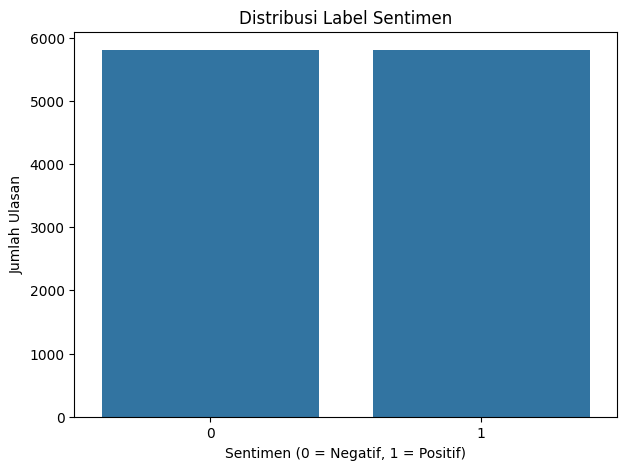

In [6]:
plt.figure(figsize=(7,5))

sns.countplot(
    data=df,
    x="sentimen"
)

plt.title("Distribusi Label Sentimen")
plt.xlabel("Sentimen (0 = Negatif, 1 = Positif)")
plt.ylabel("Jumlah Ulasan")

plt.show()

In [7]:
# Membuat stemmer Bahasa Indonesia
factory = StemmerFactory()
stemmer = factory.create_stemmer()

# Membuat stopword remover
stop_factory = StopWordRemoverFactory()
stopwords = set(stop_factory.get_stop_words())

# Mempertahankan kata negasi agar makna sentimen tidak hilang
stopwords.difference_update(["tidak", "bukan", "belum", "jangan"])

# Fungsi preprocessing
def preprocessing(teks):

    # Mengatasi data kosong
    if pd.isna(teks):
        return ""

    # 1. Case Folding
    teks = str(teks).lower()

    # 2. Cleaning
    teks = re.sub(r'http\S+|www\S+', '', teks)
    teks = re.sub(r'\d+', '', teks)
    teks = re.sub(r'[^a-zA-Z\s]', ' ', teks)
    teks = re.sub(r'\s+', ' ', teks).strip()

    # 3. Tokenisasi
    tokens = teks.split()

    # 4. Stopword Removal
    tokens = [kata for kata in tokens if kata not in stopwords]

    # 5. Stemming
    tokens = [stemmer.stem(kata) for kata in tokens]

    return ' '.join(tokens)

print("Fungsi preprocessing berhasil dibuat!")

Fungsi preprocessing berhasil dibuat!


In [11]:
from tqdm.auto import tqdm

tqdm.pandas()

df["review_bersih"] = df["review"].fillna("").progress_apply(preprocessing)

print("Preprocessing berhasil!")

  0%|          | 0/11606 [00:00<?, ?it/s]

Preprocessing berhasil!


In [12]:
from functools import lru_cache
from tqdm.auto import tqdm

# Menyimpan hasil stemming kata agar tidak dihitung berulang
@lru_cache(maxsize=50000)
def stem_cepat(kata):
    return stemmer.stem(kata)

# Fungsi preprocessing yang dioptimalkan
def preprocessing_cepat(teks):

    if pd.isna(teks):
        return ""

    # 1. Case Folding
    teks = str(teks).lower()

    # 2. Cleaning
    teks = re.sub(r'http\S+|www\S+', '', teks)
    teks = re.sub(r'\d+', '', teks)
    teks = re.sub(r'[^a-zA-Z\s]', ' ', teks)
    teks = re.sub(r'\s+', ' ', teks).strip()

    # 3. Tokenisasi
    tokens = teks.split()

    # 4. Stopword Removal
    tokens = [kata for kata in tokens if kata not in stopwords]

    # 5. Stemming dengan caching
    tokens = [stem_cepat(kata) for kata in tokens]

    return ' '.join(tokens)

print("Preprocessing versi cepat berhasil dibuat!")

Preprocessing versi cepat berhasil dibuat!


In [13]:
tqdm.pandas()

df["review_bersih"] = df["review"].fillna("").progress_apply(
    preprocessing_cepat
)

print("\nPreprocessing selesai!")
print("Jumlah data:", len(df))
print("Jumlah kata unik yang diproses:", stem_cepat.cache_info().currsize)

  0%|          | 0/11606 [00:00<?, ?it/s]


Preprocessing selesai!
Jumlah data: 11606
Jumlah kata unik yang diproses: 12454


In [14]:
pd.set_option("display.max_colwidth", None)

display(
    df[["review", "review_bersih"]].head(10)
)

,review,review_bersih
0,Suara dan mic puas. Hanya saya pesan yg nyala dan sudah sy pastikan lg klik yg nyala tp yg datang ga nyala,suara mic puas pesan yg nyala sy pasti lg klik yg nyala tp yg datang ga nyala
1,Good. Mudah-mudahan awet. Makasih,good mudah mudah awet makasih
2,"kondisi dus robek2, tolong di perhatikan lagi",kondisi dus robek perhati
3,Kualitas produk baik. Harga terjangkau dan pengirimannya cepet banget. Udh 3x order disini oke lah tp sayangnya klo buat kado gabisa nitip pake kartu ucapan atau dibungkus pake kertas kado :(,kualitas produk baik harga jangkau kirim cepet banget udh x order sini oke lah tp sayang klo buat kado gabisa nitip pake kartu ucap bungkus pake kertas kado
4,"Overall bagus, tombol berfungsi semuanya, tapi packaging kurang karena sudah penyot dan robek sedikit",overall bagus tombol fungsi semua packaging kurang penyot robek sedikit
5,"Produk ini original, Dan kualitasnya sangat baik. kecepatan pengiriman sanagt cepat, recommended seller.",produk original kualitas sangat baik cepat kirim sanagt cepat recommended seller
6,kualitas sangat jelek. bocor,kualitas sangat jelek bocor
7,"terimakasih banyak ka ya, barang sudah diterima dengan baik. sukses terus ka",terimakasih banyak ka barang terima baik sukses terus ka
8,"Body nya lebih berat dari cm 1579, spiral nya lebih tipis dibanding cm 1579, semoga awet, beli CM 1659 penasaran Aja, yang cm 1579 udah mau rusak mesin nya, Harga lebih murah 4k dari cm 1579 Fast delivery, courier Ramah sangat, ty seller",body nya lebih berat cm spiral nya lebih tipis banding cm moga awet beli cm penasaran aja cm udah mau rusak mesin nya harga lebih murah k cm fast delivery courier ramah sangat ty seller
9,pesanan di terima tanggal 27 January 2021 tetapi baru bisa saya buka pagi ini tanggal 29 January 2021 pukul 06.00 dan ternyata tab SKETSA ADVAN tidak bisa di nyalakan sama sekali dan di cas juga posisi Tab tidak bisa menyala,pesan terima tanggal january baru buka pagi tanggal january pukul nyata tab sketsa advan tidak nyala sama sekali cas posisi tab tidak nyala


In [15]:
from functools import lru_cache
from tqdm.auto import tqdm

@lru_cache(maxsize=50000)
def stem_cepat(kata):
    return stemmer.stem(kata)

def preprocessing_cepat(teks):
    if pd.isna(teks):
        return ""

    teks = str(teks).lower()
    teks = re.sub(r'http\S+|www\S+', '', teks)
    teks = re.sub(r'\d+', '', teks)
    teks = re.sub(r'[^a-zA-Z\s]', ' ', teks)
    teks = re.sub(r'\s+', ' ', teks).strip()

    tokens = teks.split()
    tokens = [kata for kata in tokens if kata not in stopwords]
    tokens = [stem_cepat(kata) for kata in tokens]

    return ' '.join(tokens)

print("Preprocessing cepat berhasil dibuat!")

Preprocessing cepat berhasil dibuat!


In [16]:
tqdm.pandas()

df["review_bersih"] = df["review"].fillna("").progress_apply(
    preprocessing_cepat
)

print("Preprocessing selesai!")

  0%|          | 0/11606 [00:00<?, ?it/s]

Preprocessing selesai!


In [17]:
pd.set_option("display.max_colwidth", None)

display(
    df[["review", "review_bersih"]].head(10)
)

,review,review_bersih
0,Suara dan mic puas. Hanya saya pesan yg nyala dan sudah sy pastikan lg klik yg nyala tp yg datang ga nyala,suara mic puas pesan yg nyala sy pasti lg klik yg nyala tp yg datang ga nyala
1,Good. Mudah-mudahan awet. Makasih,good mudah mudah awet makasih
2,"kondisi dus robek2, tolong di perhatikan lagi",kondisi dus robek perhati
3,Kualitas produk baik. Harga terjangkau dan pengirimannya cepet banget. Udh 3x order disini oke lah tp sayangnya klo buat kado gabisa nitip pake kartu ucapan atau dibungkus pake kertas kado :(,kualitas produk baik harga jangkau kirim cepet banget udh x order sini oke lah tp sayang klo buat kado gabisa nitip pake kartu ucap bungkus pake kertas kado
4,"Overall bagus, tombol berfungsi semuanya, tapi packaging kurang karena sudah penyot dan robek sedikit",overall bagus tombol fungsi semua packaging kurang penyot robek sedikit
5,"Produk ini original, Dan kualitasnya sangat baik. kecepatan pengiriman sanagt cepat, recommended seller.",produk original kualitas sangat baik cepat kirim sanagt cepat recommended seller
6,kualitas sangat jelek. bocor,kualitas sangat jelek bocor
7,"terimakasih banyak ka ya, barang sudah diterima dengan baik. sukses terus ka",terimakasih banyak ka barang terima baik sukses terus ka
8,"Body nya lebih berat dari cm 1579, spiral nya lebih tipis dibanding cm 1579, semoga awet, beli CM 1659 penasaran Aja, yang cm 1579 udah mau rusak mesin nya, Harga lebih murah 4k dari cm 1579 Fast delivery, courier Ramah sangat, ty seller",body nya lebih berat cm spiral nya lebih tipis banding cm moga awet beli cm penasaran aja cm udah mau rusak mesin nya harga lebih murah k cm fast delivery courier ramah sangat ty seller
9,pesanan di terima tanggal 27 January 2021 tetapi baru bisa saya buka pagi ini tanggal 29 January 2021 pukul 06.00 dan ternyata tab SKETSA ADVAN tidak bisa di nyalakan sama sekali dan di cas juga posisi Tab tidak bisa menyala,pesan terima tanggal january baru buka pagi tanggal january pukul nyata tab sketsa advan tidak nyala sama sekali cas posisi tab tidak nyala


In [18]:
print("Jumlah data:", len(df))
print("Data kosong sebelum:", df["review"].isna().sum())
print("Data kosong sesudah:", df["review_bersih"].isna().sum())

print("\nContoh hasil preprocessing:")
print(df["review_bersih"].head(5).tolist())

Jumlah data: 11606
Data kosong sebelum: 0
Data kosong sesudah: 0

Contoh hasil preprocessing:
['suara mic puas pesan yg nyala sy pasti lg klik yg nyala tp yg datang ga nyala', 'good mudah mudah awet makasih', 'kondisi dus robek perhati', 'kualitas produk baik harga jangkau kirim cepet banget udh x order sini oke lah tp sayang klo buat kado gabisa nitip pake kartu ucap bungkus pake kertas kado', 'overall bagus tombol fungsi semua packaging kurang penyot robek sedikit']


Pengaruh Preprocessing terhadap Kualitas Data Teks

Preprocessing merupakan tahap penting dalam pengolahan data teks. Case folding membuat seluruh huruf menjadi kecil sehingga format teks menjadi seragam. Cleaning menghilangkan URL, angka, tanda baca, dan karakter khusus yang tidak diperlukan. Tokenisasi memisahkan kalimat menjadi kata-kata. Stopword removal menghilangkan kata-kata yang kurang memiliki makna penting, sedangkan stemming mengubah kata menjadi bentuk dasarnya.

Dengan preprocessing, data teks menjadi lebih bersih, terstruktur, dan konsisten sehingga dapat mempermudah proses analisis sentimen. Namun, preprocessing juga harus dilakukan dengan hati-hati agar tidak menghilangkan kata yang memiliki makna penting dalam ulasan.

In [19]:
pd.set_option("display.max_colwidth", None)

display(df[["review", "review_bersih"]].head(10))

,review,review_bersih
0,Suara dan mic puas. Hanya saya pesan yg nyala dan sudah sy pastikan lg klik yg nyala tp yg datang ga nyala,suara mic puas pesan yg nyala sy pasti lg klik yg nyala tp yg datang ga nyala
1,Good. Mudah-mudahan awet. Makasih,good mudah mudah awet makasih
2,"kondisi dus robek2, tolong di perhatikan lagi",kondisi dus robek perhati
3,Kualitas produk baik. Harga terjangkau dan pengirimannya cepet banget. Udh 3x order disini oke lah tp sayangnya klo buat kado gabisa nitip pake kartu ucapan atau dibungkus pake kertas kado :(,kualitas produk baik harga jangkau kirim cepet banget udh x order sini oke lah tp sayang klo buat kado gabisa nitip pake kartu ucap bungkus pake kertas kado
4,"Overall bagus, tombol berfungsi semuanya, tapi packaging kurang karena sudah penyot dan robek sedikit",overall bagus tombol fungsi semua packaging kurang penyot robek sedikit
5,"Produk ini original, Dan kualitasnya sangat baik. kecepatan pengiriman sanagt cepat, recommended seller.",produk original kualitas sangat baik cepat kirim sanagt cepat recommended seller
6,kualitas sangat jelek. bocor,kualitas sangat jelek bocor
7,"terimakasih banyak ka ya, barang sudah diterima dengan baik. sukses terus ka",terimakasih banyak ka barang terima baik sukses terus ka
8,"Body nya lebih berat dari cm 1579, spiral nya lebih tipis dibanding cm 1579, semoga awet, beli CM 1659 penasaran Aja, yang cm 1579 udah mau rusak mesin nya, Harga lebih murah 4k dari cm 1579 Fast delivery, courier Ramah sangat, ty seller",body nya lebih berat cm spiral nya lebih tipis banding cm moga awet beli cm penasaran aja cm udah mau rusak mesin nya harga lebih murah k cm fast delivery courier ramah sangat ty seller
9,pesanan di terima tanggal 27 January 2021 tetapi baru bisa saya buka pagi ini tanggal 29 January 2021 pukul 06.00 dan ternyata tab SKETSA ADVAN tidak bisa di nyalakan sama sekali dan di cas juga posisi Tab tidak bisa menyala,pesan terima tanggal january baru buka pagi tanggal january pukul nyata tab sketsa advan tidak nyala sama sekali cas posisi tab tidak nyala


In [20]:
pd.set_option("display.max_colwidth", None)

hasil_contoh = df[["review", "review_bersih"]].head(10)

display(hasil_contoh)

,review,review_bersih
0,Suara dan mic puas. Hanya saya pesan yg nyala dan sudah sy pastikan lg klik yg nyala tp yg datang ga nyala,suara mic puas pesan yg nyala sy pasti lg klik yg nyala tp yg datang ga nyala
1,Good. Mudah-mudahan awet. Makasih,good mudah mudah awet makasih
2,"kondisi dus robek2, tolong di perhatikan lagi",kondisi dus robek perhati
3,Kualitas produk baik. Harga terjangkau dan pengirimannya cepet banget. Udh 3x order disini oke lah tp sayangnya klo buat kado gabisa nitip pake kartu ucapan atau dibungkus pake kertas kado :(,kualitas produk baik harga jangkau kirim cepet banget udh x order sini oke lah tp sayang klo buat kado gabisa nitip pake kartu ucap bungkus pake kertas kado
4,"Overall bagus, tombol berfungsi semuanya, tapi packaging kurang karena sudah penyot dan robek sedikit",overall bagus tombol fungsi semua packaging kurang penyot robek sedikit
5,"Produk ini original, Dan kualitasnya sangat baik. kecepatan pengiriman sanagt cepat, recommended seller.",produk original kualitas sangat baik cepat kirim sanagt cepat recommended seller
6,kualitas sangat jelek. bocor,kualitas sangat jelek bocor
7,"terimakasih banyak ka ya, barang sudah diterima dengan baik. sukses terus ka",terimakasih banyak ka barang terima baik sukses terus ka
8,"Body nya lebih berat dari cm 1579, spiral nya lebih tipis dibanding cm 1579, semoga awet, beli CM 1659 penasaran Aja, yang cm 1579 udah mau rusak mesin nya, Harga lebih murah 4k dari cm 1579 Fast delivery, courier Ramah sangat, ty seller",body nya lebih berat cm spiral nya lebih tipis banding cm moga awet beli cm penasaran aja cm udah mau rusak mesin nya harga lebih murah k cm fast delivery courier ramah sangat ty seller
9,pesanan di terima tanggal 27 January 2021 tetapi baru bisa saya buka pagi ini tanggal 29 January 2021 pukul 06.00 dan ternyata tab SKETSA ADVAN tidak bisa di nyalakan sama sekali dan di cas juga posisi Tab tidak bisa menyala,pesan terima tanggal january baru buka pagi tanggal january pukul nyata tab sketsa advan tidak nyala sama sekali cas posisi tab tidak nyala


Kesimpulan

Berdasarkan hasil pengolahan dataset ulasan e-commerce berbahasa Indonesia, preprocessing berhasil dilakukan terhadap 11.606 data ulasan. Tahapan preprocessing meliputi case folding, cleaning, tokenisasi, stopword removal, dan stemming.

Preprocessing membantu menghasilkan teks yang lebih bersih, seragam, dan terstruktur sehingga memudahkan proses analisis sentimen.